The ultimate role of this notebook is to build a dense and sparse vector index. We will explore the dataset, solve any immediate problems, decide on a chunking strategy, convert our chunks to embeddings and build vector indexes.

In [2]:
!pip install -U nltk

  Using cached nltk-3.10.3-py3-none-any.whl.metadata (3.2 kB)
Using cached nltk-3.10.3-py3-none-any.whl (1.8 MB)


In [3]:
# All import statements are added here

import re
import faiss
import pickle
import numpy as np
from pathlib import Path
from rank_bm25 import BM25Okapi
import matplotlib.pyplot as plt
from langchain_core.documents import Document
from sentence_transformers import SentenceTransformer
from datasets import load_dataset, concatenate_datasets
from langchain_text_splitters import RecursiveCharacterTextSplitter
from nltk.tokenize import word_tokenize

The dataset is already split into train-test-validation but since we are not training any models we can combine them together for an even larger corpus. 

In [4]:
dataset_locations = {
    "train": ".\\dataset\\wiki.train.tokens",
    "validation": ".\\dataset\\wiki.valid.tokens",
    "test": ".\\dataset\\wiki.test.tokens",
}


# Load the three files using Hugging Face Datasets
datasets = load_dataset(
    "text",
    data_files={
        split: str(path)
        for split, path in dataset_locations.items()
    }
)

datasets

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 1801350
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
})

In [5]:
# LET US TAKE A LOOK AT THE BEGINNING OF EACH DATASET SPLIT

for split, data in datasets.items():
    print(f"\n--- {split.upper()} ---")
    print("\n".join(data["text"][:10]))


--- TRAIN ---
 
 = Valkyria Chronicles III = 
 
 Senjō no Valkyria 3 : <unk> Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " <unk> Raven " . 
 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving for 

We can notice that each topic is denoted with = TOPIC NAME = ; Each sub topic is denoted with = = SUBTOPIC == ; and finally each sub heading is denoted as = = = SUBHEADING = = =.

In [6]:
# With the help of some regular expressions we can inspect how many articles are present in each split

for split, data in datasets.items():
    n = sum(bool(re.fullmatch(r"^\s*=\s+[^=].*[^=]\s+=\s*$", line.strip())) for line in data["text"])
    print(f"{split:>10}: {n:,} topics")

     train: 29,436 topics
validation: 60 topics
      test: 62 topics


We can conclude that there are about 29500 Wikipedia articles in total.

In [7]:
# Now let us combine the 3 datasets into 1.

data = concatenate_datasets(list(datasets.values()))

print(data)

Dataset({
    features: ['text'],
    num_rows: 1809468
})


Before proceeding to chunking we will split each article (topic) into its own element in a list. That way we can handle individual articles while chunking which would prevent spillage (parts of topic A into topic B) or cutting off an article and losing its semantic value.

In [8]:
# We will now split each topic into list elements. Each element is an entire article.

topic_pattern = re.compile(r"^\s*=\s+[^=].*[^=]\s+=\s*$")

topics = []
current = []

for line in data["text"]:
    if topic_pattern.fullmatch(line):
        if current:
            topics.append("\n".join(current))
        current = [line]
    elif current:
        current.append(line)

if current:
    topics.append("\n".join(current))

print(f"Topics extracted: {len(topics):,}")

Topics extracted: 29,558


In [9]:
# Let us see how each article now looks like.

print(topics[0])

 = Valkyria Chronicles III = 
 
 Senjō no Valkyria 3 : <unk> Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " <unk> Raven " . 
 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving for series newcomers 

Headings and subheadings could be used as metadata for chunks so that's why we will use topics list to create a dictionary that contains article names (topics), sub topics and sub headings plus the text under each section.

In [10]:
section_patterns = {
    1: re.compile(r"^\s*=\s+([^=].*[^=])\s+=\s*$"),
    2: re.compile(r"^\s*=\s+=\s+([^=].*[^=])\s+=\s+=\s*$"),
    3: re.compile(r"^\s*=\s+=\s+=\s+([^=].*[^=])\s+=\s+=\s+=\s*$"),
}

sections = []

for topic in topics:
    title = section_patterns[1].match(topic.splitlines()[0]).group(1).strip()
    sub_topic = sub_heading = None
    content = []

    for line in topic.splitlines()[1:]:
        heading = next(
            ((level, pattern.fullmatch(line).group(1).strip())
             for level, pattern in section_patterns.items()
             if pattern.fullmatch(line)),
            None
        )

        if heading:
            if text := "\n".join(content).strip():
                sections.append({
                    "title": title,
                    "sub_topic": sub_topic,
                    "sub_heading": sub_heading,
                    "text": text,
                })
                content = []
        
            level, name = heading
        
            if level == 2:
                sub_topic, sub_heading = name, None
            elif level == 3:
                sub_heading = name

        else:
            content.append(line)

    if text := "\n".join(content).strip():
        sections.append({
            "title": title,
            "sub_topic": sub_topic,
            "sub_heading": sub_heading,
            "text": text,
        })

print(f"Sections extracted: {len(sections):,}")
print(sections[0])

Sections extracted: 256,982
{'title': 'Valkyria Chronicles III', 'sub_topic': None, 'sub_heading': None, 'text': 'Senjō no Valkyria 3 : <unk> Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " <unk> Raven " . \n The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent m

In [11]:
print(sections[99])

{'title': 'Ancient Egyptian deities', 'sub_topic': 'Characteristics', 'sub_heading': 'Locations', 'text': "Gods were linked with specific regions of the universe . In Egyptian tradition , the world includes the earth , the sky , and the Duat . Surrounding them is the dark formlessness that existed before creation . The gods in general were said to dwell in the sky , although gods whose roles were linked with other parts of the universe were said to live in those places instead . Most events of mythology , set in a time before the gods ' withdrawal from the human realm , take place in an earthly setting . The deities there sometimes interact with those in the sky . The Duat , in contrast , is treated as a remote and inaccessible place , and the gods who dwell there have difficulty communicating with those in the world of the living . The space outside the cosmos is also said to be very distant . It too is inhabited by deities , some hostile and some beneficial to the other gods and thei

We have extracted the necessary information for chunking and also have taken care of empty sections in the data. Now we move on to chunking with LangChain.

Before deciding a number for splitting text into chunks I think its best to see how many "words" do we have per section. We will use numpy to calculate the basic metrics such as median and percentiles and then decide on a number.

In [12]:
section_word_counts = np.array([
    len(section["text"].split())
    for section in sections
    if section["text"].strip()
])

print(f"Sections: {len(section_word_counts):,}")
print(f"Minimum:  {section_word_counts.min():,} words")
print(f"Maximum:  {section_word_counts.max():,} words")
print(f"Mean:     {section_word_counts.mean():,.1f} words")
print(f"Median:   {np.median(section_word_counts):,.1f} words")
print(f"P25:      {np.percentile(section_word_counts, 25):,.1f} words")
print(f"P75:      {np.percentile(section_word_counts, 75):,.1f} words")
print(f"P90:      {np.percentile(section_word_counts, 90):,.1f} words")
print(f"P95:      {np.percentile(section_word_counts, 95):,.1f} words")
print(f"P99:      {np.percentile(section_word_counts, 99):,.1f} words")

Sections: 256,982
Minimum:  1 words
Maximum:  14,250 words
Mean:     388.4 words
Median:   313.0 words
P25:      177.0 words
P75:      506.0 words
P90:      757.0 words
P95:      959.0 words
P99:      1,545.0 words


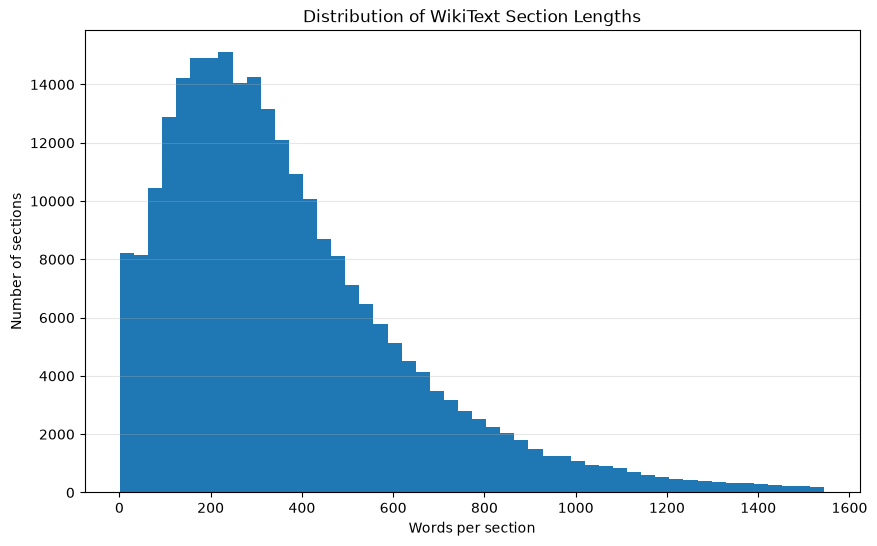

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(
    section_word_counts[section_word_counts <= np.percentile(section_word_counts, 99)],
    bins=50
)

plt.xlabel("Words per section")
plt.ylabel("Number of sections")
plt.title("Distribution of WikiText Section Lengths")
plt.grid(axis="y", alpha=0.3)

plt.show()

We can see that 95% of sections contain fewer than 1000 words so we may use a condition to chunk the rest ~5% which are over 1000 words and leave the 95% as it is.

Also instead of fixed number splitting, we can use something like recursive character based splitting. That way we are not cutting something off mid sentence or mid word.

Now we proceed to use LangChain for splitting our text into chunks.

In [14]:
# Simple length of text function for langchain

def word_count(text):
    return len(text.split())

splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=0,
    length_function=word_count,
    separators=["\n\n", "\n", ". ", " ", ""],
)

chunks = []


# For each section's text, we split it into chunks if necessary and append all text into split_texts.
# Then each split_text is appended to chunks dictionary.
# Chunks dictionary contains each chunk plus its relative heading and subheadings. We can use this as metadata for filtering.

for section in sections:
    text = section["text"]

    split_texts = splitter.split_text(text)

    for chunk_text in split_texts:
        chunks.append({
            "title": section["title"],
            "sub_topic": section["sub_topic"],
            "sub_heading": section["sub_heading"],
            "text": chunk_text,
        })

print(f"Chunks created: {len(chunks):,}")

Chunks created: 270,296


LangChain created about 270,000 chunks. Let's inspect a few at random.

In [15]:
chunks[100]

{'title': 'Ancient Egyptian deities',
 'sub_topic': 'Characteristics',
 'sub_heading': None,
 'text': "Modern knowledge of Egyptian beliefs about the gods is mostly drawn from religious writings produced by the nation 's scribes and priests . These people were the elite of Egyptian society and were very distinct from the general populace , most of whom were illiterate . Little is known about how well this broader population knew or understood the sophisticated ideas that the elite developed . Commoners ' perceptions of the divine may have differed from those of the priests . The populace may , for example , have mistaken the religion 's symbolic statements about the gods and their actions for literal truth . But overall , what little is known about popular religious belief is consistent with the elite tradition . The two traditions form a largely cohesive vision of the gods and their nature ."}

In [16]:
chunks[101]

{'title': 'Ancient Egyptian deities',
 'sub_topic': 'Characteristics',
 'sub_heading': 'Roles',
 'text': 'Most Egyptian deities represent natural or social phenomena . The gods were generally said to be immanent in these phenomena — to be present within nature . The types of phenomena they represented include physical places and objects as well as abstract concepts and forces . The god Shu was the deification of all the world \'s air ; the goddess <unk> oversaw a limited region of the earth , the Theban Necropolis ; and the god Sia personified the abstract notion of perception . Major gods often had many roles and were involved in several types of phenomena . For instance , Khnum was the god of Elephantine Island in the midst of the Nile , the river that was essential to Egyptian civilization . He was credited with producing the annual Nile flood that fertilized the nation \'s farmland . Perhaps as an outgrowth of this life @-@ giving function , he was said to create all living things 

Let us save the chunks in a pickle file in order to refer to it later for retrieval.

In [17]:
chunk_store = [
    {
        "text": chunk["text"],
        "metadata": {"title": chunk["title"], "sub_topic":chunk["sub_topic"],"sub_heading":chunk["sub_heading"]}
    }
    for chunk in chunks
]

with open("chunk_store.pkl", "wb") as f:
    pickle.dump(chunk_store, f)

print(f"Saved {len(chunk_store):,} chunks.")

Saved 270,296 chunks.


We will use the BAAI be-base-en-v1.5 embedding model from Sentence Transformer to create the vector embedding for each chunk. This is an intensive operation and will take a lot of time if done with CPU.

In [16]:
# DO NOT RUN THIS UNLESS TORCH IS ABLE TO USE GPU FOR INFERENCE
# OR ELSE THIS WILL TAKE A MILLION YEARS TO COMPUTE!

# embedding_model = SentenceTransformer("BAAI/bge-base-en-v1.5")

# texts = [chunk["text"] for chunk in chunks]

# embeddings = embedding_model.encode(
#     texts,
#     batch_size=32,
#     show_progress_bar=True,
#     normalize_embeddings=True,
#     convert_to_numpy=True,
# )

# print(f"Shape: {embeddings.shape}")
# print(f"Dtype: {embeddings.dtype}")

Inference done via AMD Radeon RX 6900XT 16GB GPU using AMD ROCM backend on macOS since PyTorch ROCM does not support that GPU in Windows. Total time - ~37 minutes.

In [17]:
# Save the embeddings in a numpy array
# Don't run it again unless needed.
# np.save("embeddings.npy", embeddings)

We will now utilize a conventional dense vector storage to store and query vector embedding. For our project we will proceed with FAISS.

In [23]:
# Load the previously save embeddings.npy file.

embeddings = np.load("embeddings.npy")

print("Loaded shape:", embeddings.shape)
print("Loaded dtype:", embeddings.dtype)
print("Embeddings loaded successfully.")

Loaded shape: (270296, 768)
Loaded dtype: float32
Embeddings loaded successfully.


We will normalize our vectors and then store it in the FAISS index. Normalizing, i.e., transforming every vector to unit length is a common step during this process so that FAISS's inner product similarity becomes cosine similarity.

In [24]:
faiss.normalize_L2(embeddings)

index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)

print("Vectors indexed:", index.ntotal)

Vectors indexed: 270296


Save vectors to FAISS index.

In [25]:
faiss.write_index(index, "dense_index.faiss")

We will now build a sparse vector index. We will combine dense and sparse search into a hybrid system for best results. For this we have chosen the conventional BM25 Sparse Index.

In [18]:
corpus = [chunk["text"] for chunk in chunks]

# Tokenization with NLTK Library. 
# We need to do this or else simple whitespace tokenizing would mean "richard" are treated differently"richard's"
tokenized_corpus = [word_tokenize(text.lower()) for text in corpus]
bm25 = BM25Okapi(tokenized_corpus)

print("Documents indexed:", len(tokenized_corpus))

Documents indexed: 270296


In [19]:
with open("bm25_index.pkl", "wb") as f:
    pickle.dump(bm25, f)

print("BM25 index saved.")

BM25 index saved.
